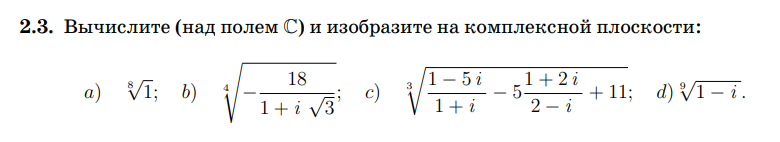

## Алгоритм решения

Для каждого пункта задачи используется следующий порядок:

1. **Упростить выражение** под корнем и привести его к виду $z=a+bi$.

$$
w^n=z.
$$

2. **Найти модуль**:
$$
r=\sqrt{a^2+b^2}.
$$

3. **Получить угол $\varphi$**:

$$
\cos\varphi = \frac{a}{r},\qquad
\sin\varphi = \frac{b}{r}.
$$

4. **Применить формулу корней для каждого k**:

$$
w_k=
   \sqrt[n]{r}
   \left(
   \cos\frac{\varphi+2\pi k}{n}
   +i\sin\frac{\varphi+2\pi k}{n}
   \right),
   \quad k=0,\ldots,n-1.
$$

5. **Получить координаты:**

Для каждого значения $k$ из формулы комплексного числа: 

$$
z=a+bi,
$$

получаем координаты $(a,b)$ на комплексной плоскости.

6. **Изобразить корни на комплексной плоскости** как точки $(x,y)$.

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math, Markdown

I = sp.I

def roots_data(z, n):
    
    # Пункт 1 — упрощение выражения к виду комплексного числа
    z = sp.simplify(z)
    re = sp.re(z)
    im = sp.im(z)
    
    # Пункт 2 — вычисление модуля комплексного числа
    r = sp.simplify(sp.sqrt(re**2 + im**2))
    
    # Пункт 3 — вычисление аргумента комплексного числа
    phi = sp.arg(z)

    # Пункт 4 — вычисление корней комплексного числа
    roots = []
    for k in range(n):
        angle = sp.simplify((phi + 2*sp.pi*k) / n)
        root = sp.simplify(
            sp.expand_complex(
                r**(sp.Rational(1, n)) *
                (sp.cos(angle)
                 + I*sp.sin(angle))
            )
        )
        roots.append((k, angle, root))
    return z, r, phi, roots

def show_equation(label, lhs, rhs):
    display(Markdown(f"**{label}**"))
    display(Math(sp.latex(sp.Eq(lhs, rhs))))

def show_roots(roots):
    display(Markdown("**Корни:**"))
    for k, angle, root in roots:
        display(Math(
            rf"w_{{{k}}} = {sp.latex(root)}, \qquad "
            rf"\varphi_{{{k}}} = {sp.latex(angle)}"
        ))


# Пункт 5 — построение графика корней
def plot_roots(roots, title):

    points = [complex(sp.N(root)) for _, _, root in roots]
    xs = [p.real for p in points]
    ys = [p.imag for p in points]

    radius = max(np.hypot(xs, ys))
    t = np.linspace(0, 2*np.pi, 500)

    # функция создания нового графика
    plt.figure(figsize=(7, 7))
    plt.axhline(0, linewidth=1)
    plt.axvline(0, linewidth=1)
    plt.plot(radius*np.cos(t), radius*np.sin(t), linestyle="--")
    plt.scatter(xs, ys, s=60)

    for k, (x, y) in enumerate(zip(xs, ys)):
        plt.annotate(
            rf"$w_{{{k}}}$",
            (x, y),
            xytext=(6, 6),
            textcoords="offset points"
        )

    plt.xlabel("Re(z)")
    plt.ylabel("Im(z)")
    plt.title(title)
    plt.grid(True)
    plt.axis("equal")
    plt.show()


In [2]:
# z = 1 и n = 8
z_a = sp.Integer(1)
n_a = 8

# Использование функции выше roots_data для вычисления корней
z_a, r_a, phi_a, roots_a = roots_data(z_a, n_a)

show_equation("Число под корнем:", sp.Symbol("z"), z_a)
show_equation("Модуль:", sp.Symbol("r"), r_a)
show_equation("Аргумент:", sp.Symbol(r"\varphi"), phi_a)

display(Markdown("**Тригонометрическая форма:**"))
display(Math(
    rf"z = {sp.latex(r_a)}"
    rf"\left(\cos({sp.latex(phi_a)}) + "
    rf"i\sin({sp.latex(phi_a)})\right)"
))

show_roots(roots_a)


**Число под корнем:**

<IPython.core.display.Math object>

**Модуль:**

<IPython.core.display.Math object>

**Аргумент:**

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

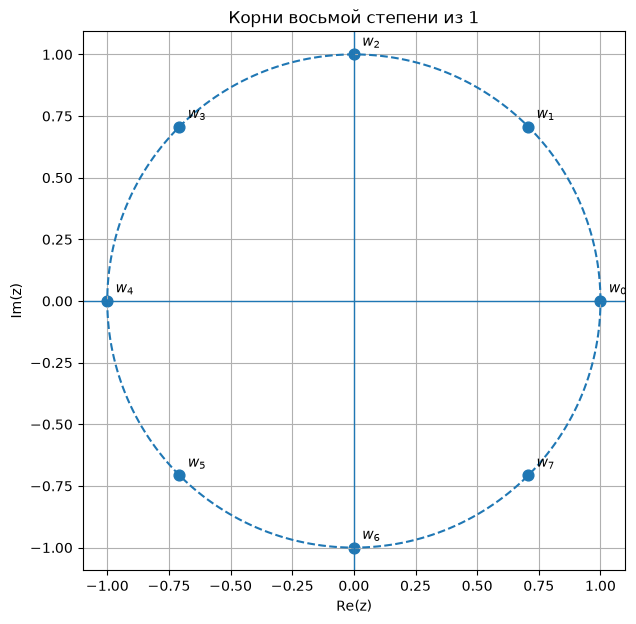

In [3]:
plot_roots(roots_a, "Корни восьмой степени из 1")

In [4]:
z_b = sp.simplify(-18 / (1 + I*sp.sqrt(3)))
z_b = sp.expand_complex(z_b)
n_b = 4

show_equation("Упрощённое выражение:", sp.Symbol("z"), z_b)

z_b, r_b, phi_b, roots_b = roots_data(z_b, n_b)

show_equation("Модуль:", sp.Symbol("r"), r_b)
show_equation("Аргумент:", sp.Symbol(r"\varphi"), phi_b)

display(Markdown("**Тригонометрическая форма:**"))
display(Math(
    rf"z = {sp.latex(r_b)}"
    rf"\left(\cos({sp.latex(phi_b)}) + "
    rf"i\sin({sp.latex(phi_b)})\right)"
))

show_roots(roots_b)


**Упрощённое выражение:**

<IPython.core.display.Math object>

**Модуль:**

<IPython.core.display.Math object>

**Аргумент:**

...

**Корни:**

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

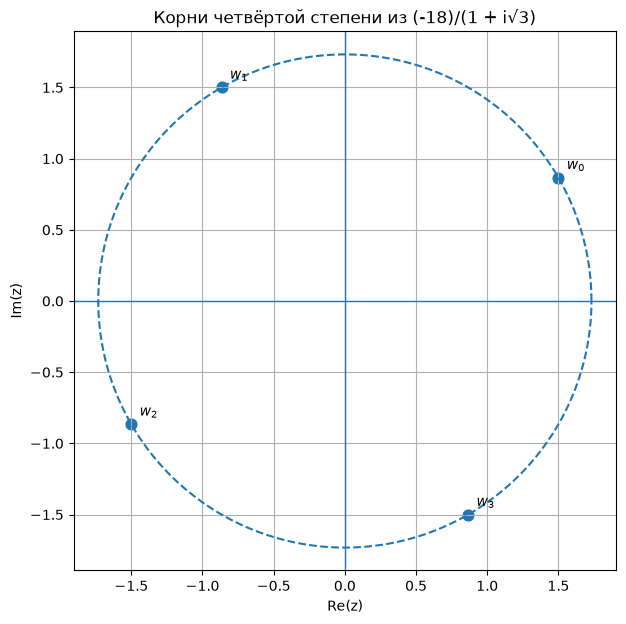

In [5]:
plot_roots(roots_b, "Корни четвёртой степени из (-18)/(1 + i√3)")

In [7]:
frac1_c = sp.simplify((1 - 5*I) / (1 + I))
frac2_c = sp.simplify((1 + 2*I) / (2 - I))
z_c = sp.simplify(frac1_c - 5*frac2_c + 11)
z_c = sp.expand_complex(z_c)
n_c = 3

show_equation("Первая дробь:", sp.Symbol("A"), frac1_c)
show_equation("Вторая дробь:", sp.Symbol("B"), frac2_c)
show_equation("Выражение под корнем:", sp.Symbol("z"), z_c)

z_c, r_c, phi_c, roots_c = roots_data(z_c, n_c)

show_equation("Модуль:", sp.Symbol("r"), r_c)
show_equation("Аргумент:", sp.Symbol(r"\varphi"), phi_c)

display(Markdown("**Тригонометрическая форма:**"))
display(Math(
    rf"z = {sp.latex(r_c)}"
    rf"\left(\cos({sp.latex(phi_c)}) + "
    rf"i\sin({sp.latex(phi_c)})\right)"
))

show_roots(roots_c)


**Первая дробь:**

<IPython.core.display.Math object>

**Вторая дробь:**

<IPython.core.display.Math object>

**Выражение под корнем:**

...

<IPython.core.display.Math object>

**Корни:**

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

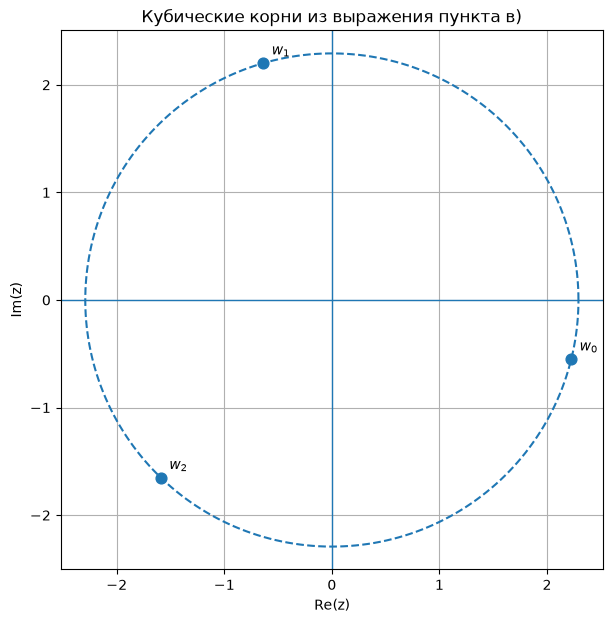

In [8]:
plot_roots(roots_c, "Кубические корни из выражения пункта в)")

In [9]:
z_d = 1 - I
n_d = 9

z_d, r_d, phi_d, roots_d = roots_data(z_d, n_d)

show_equation("Число под корнем:", sp.Symbol("z"), z_d)
show_equation("Модуль:", sp.Symbol("r"), r_d)
show_equation("Аргумент:", sp.Symbol(r"\varphi"), phi_d)

display(Markdown("**Тригонометрическая форма:**"))
display(Math(
    rf"z = {sp.latex(r_d)}"
    rf"\left(\cos({sp.latex(phi_d)}) + "
    rf"i\sin({sp.latex(phi_d)})\right)"
))

show_roots(roots_d)

**Число под корнем:**

<IPython.core.display.Math object>

**Модуль:**

<IPython.core.display.Math object>

**Аргумент:**

...

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

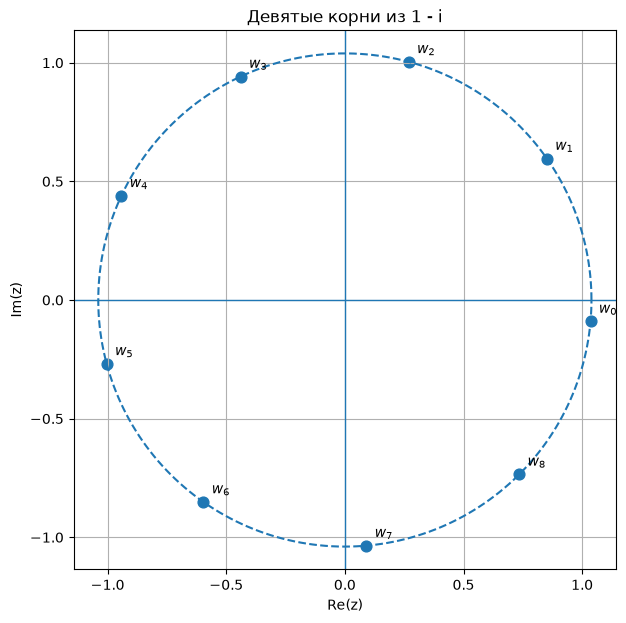

In [10]:
plot_roots(roots_d, "Девятые корни из 1 - i")